# Matching two surveys: minutes or milliseconds

A data structure decides how much work each operation costs, and that cost is
invisible in the code: `x in a` looks the same whether `a` is a list or a set.
This notebook times one common task, matching respondents across two surveys
by their id, and then looks inside binary search to count how many steps it
really takes.

## 1. Which respondents answered both surveys?

Two surveys, each with $n$ respondent ids. We want the ids that appear in
both. The first version keeps the ids of survey A in a list and asks, for every
id of survey B, whether it is in that list. The second version keeps them in a
set, which is a hash table underneath. Watch how the two times change when
$n$ doubles.

In [1]:
import random, time

def make_surveys(n, seed=3):
    rnd = random.Random(seed)
    ids = rnd.sample(range(10 * n), 2 * n)      # 2n distinct ids
    return ids[:n], ids[n // 2: n // 2 + n]     # half of them overlap

def matched_with_list(a, b):
    a_list = list(a)
    return [x for x in b if x in a_list]        # scans the list for every x

def matched_with_set(a, b):
    a_set = set(a)
    return [x for x in b if x in a_set]         # hashes x, looks in one slot

sizes, t_list, t_set = [], [], []
for n in [1_000, 2_000, 4_000, 8_000, 16_000]:
    a, b = make_surveys(n)
    t0 = time.perf_counter(); m1 = matched_with_list(a, b); t_list.append(time.perf_counter() - t0)
    t0 = time.perf_counter(); m2 = matched_with_set(a, b); t_set.append(time.perf_counter() - t0)
    sizes.append(n)
    assert sorted(m1) == sorted(m2)
    print(f"n = {n:>6}   list {t_list[-1]:7.3f} s   set {t_set[-1]:8.5f} s   ratio {t_list[-1] / t_set[-1]:6.0f}x")

n =   1000   list   0.006 s   set  0.00011 s   ratio     57x
n =   2000   list   0.012 s   set  0.00010 s   ratio    120x
n =   4000   list   0.051 s   set  0.00025 s   ratio    205x


n =   8000   list   0.197 s   set  0.00058 s   ratio    339x


n =  16000   list   2.049 s   set  0.00115 s   ratio   1780x


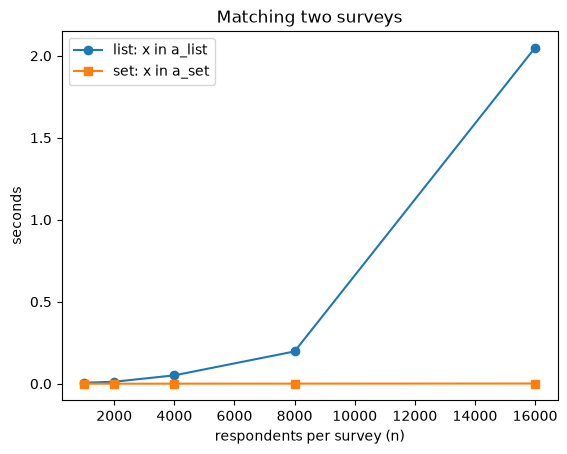

In [2]:
import matplotlib.pyplot as plt

plt.plot(sizes, t_list, "o-", label="list: x in a_list")
plt.plot(sizes, t_set, "s-", label="set: x in a_set")
plt.xlabel("respondents per survey (n)"); plt.ylabel("seconds")
plt.legend(); plt.title("Matching two surveys")
plt.show()

Doubling $n$ multiplies the list time by about four: there are twice as many
ids to look up, and each lookup scans a list that is twice as long. The set
time only doubles. At $n = 16\,000$ the list version is already more than a
thousand times slower, and for a survey of a million respondents the same
growth means hours for the list and a fraction of a second for the set. The
results are identical; only the structure differs.

## 2. Inside binary search

The lecture's second answer to slow searching is to keep the data sorted and
halve the search space at every step. We count the comparisons that a linear
scan and a binary search make when looking for the same id.

In [3]:
def linear_search(sorted_ids, target):
    comparisons = 0
    for x in sorted_ids:
        comparisons += 1
        if x == target:
            return comparisons
    return comparisons

def binary_search(sorted_ids, target):
    low, high, comparisons = 0, len(sorted_ids) - 1, 0
    while low <= high:
        mid = (low + high) // 2
        comparisons += 1
        if sorted_ids[mid] == target:
            return comparisons
        if sorted_ids[mid] < target:
            low = mid + 1
        else:
            high = mid - 1
    return comparisons

for n in [1_000, 10_000, 100_000, 1_000_000]:
    ids = list(range(0, 2 * n, 2))              # sorted ids 0, 2, 4, ...
    target = ids[-1]                            # the worst case for a scan: the last one
    print(f"n = {n:>9}   linear {linear_search(ids, target):>9} comparisons   binary {binary_search(ids, target):>3}")

n =      1000   linear      1000 comparisons   binary  10
n =     10000   linear     10000 comparisons   binary  14
n =    100000   linear    100000 comparisons   binary  17
n =   1000000   linear   1000000 comparisons   binary  20


A thousand times more data costs the linear scan a thousand times more
comparisons and costs binary search ten more. Twenty comparisons find one id
among a million, because each step halves what is left and $2^{20} > 10^6$.

Binary search has a precondition, though, and the code does not check it.
Give it a list that is not sorted and it returns an answer with the same
confidence.

In [4]:
import bisect

ids = [40, 10, 30, 20]                          # not sorted
i = bisect.bisect_left(ids, 10)                 # binary search from the standard library
print("position found:", i, "  value there:", ids[i])
print("binary search says 10 is in the list:", ids[i] == 10, "  plain scan says:", 10 in ids)

position found: 0   value there: 40
binary search says 10 is in the list: False   plain scan says: True


Binary search on unsorted data does not fail loudly, it just gives the wrong
answer. Sorting once costs more than one scan, so the trade-off is the one the
lecture describes: sort or hash when you will search many times, scan when you
will search once.

**What we used:** [the trade-off between editing and searching](https://dgarcia-eu.github.io/ICSS/Transcripts/03-DataStructures.html#binary-search-trees),
[binary search](https://dgarcia-eu.github.io/ICSS/Transcripts/03-DataStructures.html#binary-search),
[hashing and hash tables](https://dgarcia-eu.github.io/ICSS/Transcripts/03-DataStructures.html#hash-tables) and
[dictionaries](https://dgarcia-eu.github.io/ICSS/Transcripts/03-DataStructures.html#dictionaries) from session 3.